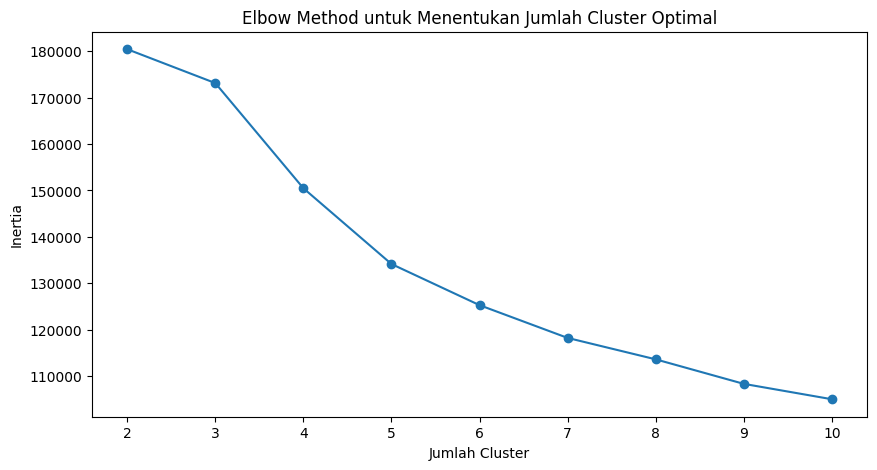

KMeans Silhouette Score - Train: 0.334
KMeans Silhouette Score - Test: 0.336


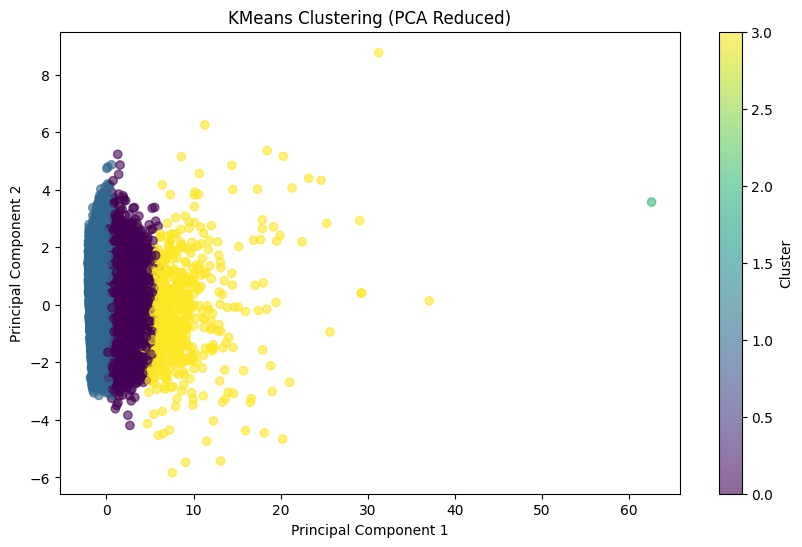

DBSCAN menemukan 35 cluster dan 13029 noise points pada data training
DBSCAN Silhouette Score - Train: -0.431


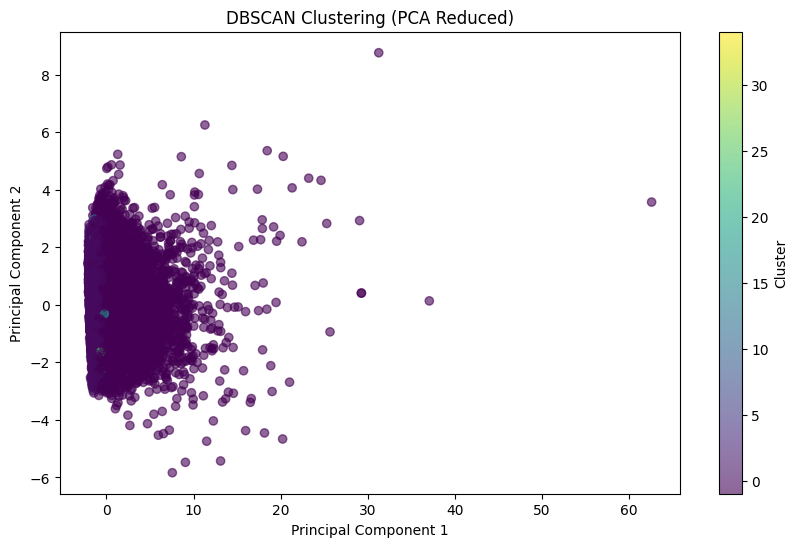


Karakteristik Cluster (KMeans):
                Attention  Meditation         Delta         Theta  \
KMeans_Cluster                                                      
0               37.933650   50.618900  1.133018e+06  2.528569e+05   
1               49.201978   52.881383  2.423503e+05  4.926793e+04   
2               24.000000   69.000000  9.083320e+05  2.268645e+06   
3               31.122222   56.946032  1.562819e+06  8.160401e+05   

                    Low Alpha    High Alpha      Low Beta      High Beta  \
KMeans_Cluster                                                             
0                49434.714129  3.378006e+04  2.438875e+04   47587.843173   
1                12727.463013  8.848949e+03  7.738416e+03   18541.801654   
2                10096.000000  1.598931e+06  1.986647e+06  520152.000000   
3               191731.879365  1.412125e+05  1.040807e+05  105026.261905   

                    Low Gamma     High Gamma  
KMeans_Cluster                                
0

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score

# Load data
data = pd.read_csv('all.csv')

# Pilih fitur yang akan digunakan untuk clustering
features = ['Attention', 'Meditation', 'Delta', 'Theta', 'Low Alpha', 'High Alpha',
            'Low Beta', 'High Beta', 'Low Gamma', 'High Gamma']
X = data[features]

# Split data menjadi training (80%) dan testing (20%)
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# Standardisasi data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 1. Clustering dengan KMeans
# Menentukan jumlah cluster optimal dengan elbow method
inertia = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_train_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow method
plt.figure(figsize=(10, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.title('Elbow Method untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster')
plt.ylabel('Inertia')
plt.show()

# Berdasarkan elbow method, pilih jumlah cluster (misalnya 4)
optimal_k = 4

# Training KMeans dengan cluster optimal
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_train_labels = kmeans.fit_predict(X_train_scaled)
kmeans_test_labels = kmeans.predict(X_test_scaled)

# Evaluasi KMeans dengan silhouette score
kmeans_train_score = silhouette_score(X_train_scaled, kmeans_train_labels)
kmeans_test_score = silhouette_score(X_test_scaled, kmeans_test_labels)

print(f"KMeans Silhouette Score - Train: {kmeans_train_score:.3f}")
print(f"KMeans Silhouette Score - Test: {kmeans_test_score:.3f}")

# Visualisasi hasil clustering (2D PCA)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_train_labels, cmap='viridis', alpha=0.6)
plt.title('KMeans Clustering (PCA Reduced)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

## 2. Clustering dengan DBSCAN
# Mencari parameter optimal untuk DBSCAN
# Kita akan mencoba beberapa kombinasi eps dan min_samples

# Contoh parameter (bisa disesuaikan)
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_train_labels = dbscan.fit_predict(X_train_scaled)

# Hitung jumlah cluster yang ditemukan (abaikan noise jika ada)
n_clusters = len(set(dbscan_train_labels)) - (1 if -1 in dbscan_train_labels else 0)
n_noise = list(dbscan_train_labels).count(-1)

print(f"DBSCAN menemukan {n_clusters} cluster dan {n_noise} noise points pada data training")

# Evaluasi DBSCAN (hanya jika ada lebih dari 1 cluster)
if n_clusters > 1:
    dbscan_train_score = silhouette_score(X_train_scaled, dbscan_train_labels)
    print(f"DBSCAN Silhouette Score - Train: {dbscan_train_score:.3f}")
else:
    print("DBSCAN hanya menemukan 1 cluster atau noise saja")

# Visualisasi DBSCAN clustering
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_train_labels, cmap='viridis', alpha=0.6)
plt.title('DBSCAN Clustering (PCA Reduced)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

# Analisis cluster
# Gabungkan label cluster dengan data asli untuk analisis
X_train_with_clusters = X_train.copy()
X_train_with_clusters['KMeans_Cluster'] = kmeans_train_labels
X_train_with_clusters['DBSCAN_Cluster'] = dbscan_train_labels

# Analisis karakteristik cluster (untuk KMeans)
cluster_means = X_train_with_clusters.groupby('KMeans_Cluster')[features].mean()
print("\nKarakteristik Cluster (KMeans):")
print(cluster_means)

# Analisis distribusi per cluster
cluster_counts = X_train_with_clusters['KMeans_Cluster'].value_counts()
print("\nDistribusi Data per Cluster (KMeans):")
print(cluster_counts)